# Physics-Constrained Synthetic Solar PV Generation
## Notebook 1 of 3: data, clear-sky physics, metrics, baseline

**Goal of this notebook:** build the real-data foundation and the yardstick every later model is judged by.

1. Download hourly PV output for one site (PVGIS)
2. Compute the physical envelope: clear-sky output via `pvlib`
3. Reshape the series into daily 24-hour profiles
4. Define evaluation metrics (fidelity, physical validity, novelty)
5. Score a seasonal-bootstrap baseline

Run on CPU. No GPU needed here.

In [ ]:
!pip -q install pvlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 43.2 MB/s eta 0:00:00


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pvlib, random, pickle
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import cdist

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ---- SITE CONFIG: change freely (any site covered by PVGIS) ----
LAT, LON   = 37.39, -5.98      # example site; swap for your own
TILT, AZ   = 30, 180           # fixed panel; azimuth 180 = facing south (northern hemisphere)
START, END = 2005, 2020        # PVGIS-SARAH2 era; widen/narrow as available
RASTER_DB  = None              # None = PVGIS default for the site. If the site is not covered, try "PVGIS-ERA5"
TEST_YEARS = 2                 # last N years held out for testing

## 1. Download real data
PVGIS returns the hourly output of a **1 kWp** PV system plus ambient temperature. Output is in watts.

In [ ]:
def fetch_pv(lat, lon, start, end, tilt, az, db=None):
    out = pvlib.iotools.get_pvgis_hourly(
        lat, lon, start=start, end=end, raddatabase=db, components=False,
        surface_tilt=tilt, surface_azimuth=az, pvcalculation=True,
        peakpower=1, loss=14, map_variables=False)
    return out[0]          # first element is the data frame in all pvlib versions

raw = fetch_pv(LAT, LON, START, END, TILT, AZ, RASTER_DB)
raw.to_csv("pv_raw.csv")   # cache so you do not re-download after a runtime reset
print(raw.shape); raw[["P","G(i)","T2m"]].describe().round(1)

(140256, 6)


,P,G(i),T2m
count,140256.0,140256.0,140256.0
mean,188.8,249.9,18.8
std,262.6,346.0,8.1
min,0.0,0.0,-2.9
25%,0.0,0.0,12.7
50%,0.0,0.0,18.0
75%,391.1,491.3,24.2
max,895.6,1132.1,43.5


## 2. The physical prior: clear-sky envelope
A real PV panel cannot (meaningfully) exceed what the sky would give it with no clouds, and it produces nothing when the sun is down. We compute clear-sky plane-of-array irradiance with `pvlib` and scale it to PV watts. This envelope is what the constrained model will use in Notebook 2.

scale K = 1.023
hours where real P exceeds envelope: 0.44%  (cloud-edge enhancement; model allows a 10% margin)


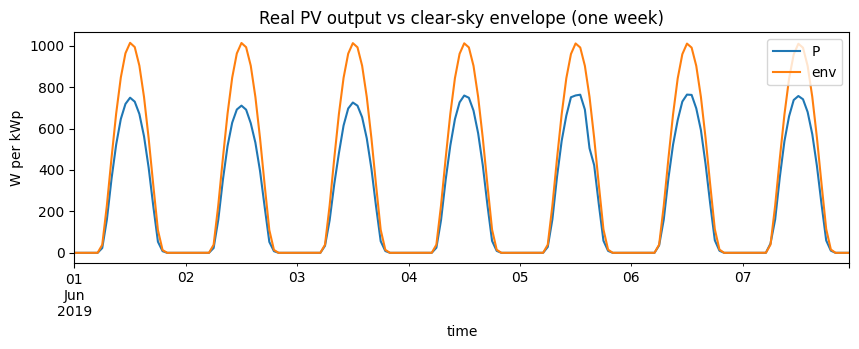

In [ ]:
def build_hourly(raw, lat, lon, tilt, az):
    df = raw[["P","T2m"]].copy()                        # keep PVGIS's own hh:10 stamps while computing solar geometry
    loc = pvlib.location.Location(lat, lon)
    cs  = loc.get_clearsky(df.index, model="ineichen")
    sp  = loc.get_solarposition(df.index)
    poa = pvlib.irradiance.get_total_irradiance(
        tilt, az, sp["apparent_zenith"], sp["azimuth"], cs["dni"], cs["ghi"], cs["dhi"])["poa_global"]
    df["poa_cs"] = poa.fillna(0).clip(lower=0)
    # scale clear-sky irradiance to watts: K = near-maximum observed P / poa_cs (daytime only)
    day = df["poa_cs"] > 50
    K = (df.loc[day,"P"] / df.loc[day,"poa_cs"]).quantile(0.995)
    df["env"] = df["poa_cs"] * K
    df["P"] = df["P"].clip(lower=0)
    df.index = df.index.floor("h")                      # now align to the hour
    df = df[~df.index.duplicated()]
    # shift UTC to local solar time so each "day" is one sun cycle
    shift = int(round(lon / 15))
    df.index = df.index + pd.Timedelta(hours=shift)
    return df, K

hourly, K = build_hourly(raw, LAT, LON, TILT, AZ)
print("scale K =", round(K,3))
share_over = (hourly["P"] > hourly["env"]*1.0).mean()
print(f"hours where real P exceeds envelope: {share_over:.2%}  (cloud-edge enhancement; model allows a 10% margin)")
ax = hourly.loc["2019-06-01":"2019-06-07", ["P","env"]].plot(figsize=(10,3), title="Real PV output vs clear-sky envelope (one week)")
ax.set_ylabel("W per kWp"); plt.show()

## 3. Daily tensors
Each training example is one day = 24 hourly values, plus conditioning information: day of year (sine/cosine) and a daily **clearness index** (actual energy / clear-sky energy). The clearness index is a one-number weather summary, so the model can be asked for 'a cloudy June day'.

days  train: 5113  test: 731
CAP=1062 W   RAMP_LIMIT=0.679 of capacity per hour


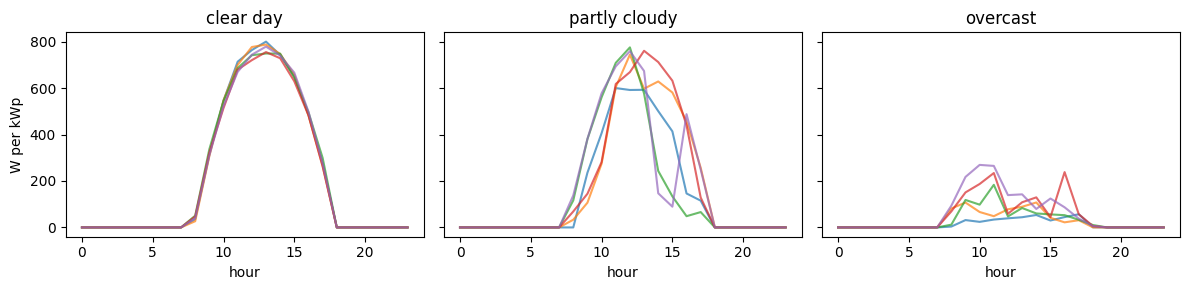

In [ ]:
def to_days(hourly):
    d = hourly.copy()
    d["date"] = d.index.date; d["hr"] = d.index.hour
    P   = d.pivot(index="date", columns="hr", values="P")
    ENV = d.pivot(index="date", columns="hr", values="env")
    ok  = P.notna().all(axis=1) & ENV.notna().all(axis=1)
    P, ENV = P[ok], ENV[ok]
    dates = pd.to_datetime(P.index)
    doy = dates.dayofyear.values
    kt  = (P.sum(axis=1) / ENV.sum(axis=1).clip(lower=1)).clip(0, 1.1).values
    return dict(P=P.values.astype(np.float32), ENV=ENV.values.astype(np.float32),
                doy=doy, kt=kt.astype(np.float32), dates=dates)

D = to_days(hourly)
years = D["dates"].year.values
test_mask  = years > years.max() - TEST_YEARS
train_mask = ~test_mask
split = lambda m: {k: v[m] for k, v in D.items()}
TR, TE = split(train_mask), split(test_mask)
print("days  train:", len(TR["P"]), " test:", len(TE["P"]))

# Physical limits measured from TRAINING data only
CAP = float(TR["ENV"].max())                              # peak envelope (W)
day = (TR["ENV"][:, 1:] > 50) & (TR["ENV"][:, :-1] > 50)
ramps_tr = (np.abs(np.diff(TR["P"], axis=1)) / CAP)[day]
RAMP_LIMIT = float(np.quantile(ramps_tr, 0.999))
print(f"CAP={CAP:.0f} W   RAMP_LIMIT={RAMP_LIMIT:.3f} of capacity per hour")

fig, ax = plt.subplots(1,3, figsize=(12,3), sharey=True)
for a, kt_rng, name in zip(ax, [(0.85,1.2),(0.5,0.7),(0,0.35)], ["clear day","partly cloudy","overcast"]):
    idx = np.where((TR["kt"]>=kt_rng[0])&(TR["kt"]<kt_rng[1]))[0][:5]
    for i in idx: a.plot(TR["P"][i], alpha=.7)
    a.set_title(name); a.set_xlabel("hour")
ax[0].set_ylabel("W per kWp"); plt.tight_layout(); plt.show()

## 4. Evaluation metrics
Four questions, asked of any synthetic set:

| Metric | Question |
|---|---|
| `wd_value`, `wd_ramp` | Do the distributions of power and hourly ramps match reality? (Wasserstein distance, lower is better) |
| `profile_rmse` | Does the average daily shape match? |
| `violation_rate` | What fraction of days break physics: output at night, negative output, above the envelope, or an impossible ramp? |
| `novelty` | How far is each synthetic day from its nearest *training* day? Near zero means memorized copies. |

Novelty matters because a method that just replays real days would otherwise look perfect.

In [ ]:
def hard_violation_rate(P, ENV, margin=1.10, night_tol=1.0):
    bad = (
        ((P > night_tol) & (ENV < night_tol)).any(1)
        | (P < -1e-6).any(1)
        | (P > ENV * margin + night_tol).any(1)
    )
    return float(bad.mean())


def ramp_exceed_rate(P, ENV):
    # Fraction of daytime hour-pairs over the limit
    d = (ENV[:, 1:] > 50) & (ENV[:, :-1] > 50)
    return float(
        (np.abs(np.diff(P, axis=1)) / CAP > RAMP_LIMIT)[d].mean()
    )


def evaluate(P_syn, ENV_syn, P_real=TE["P"], P_train=TR["P"], n_nn=1500):
    kw = lambda x: x / 1000.0
    out = {}

    out["wd_value"] = wasserstein_distance(
        kw(P_syn).ravel(), kw(P_real).ravel()
    )

    out["wd_ramp"] = wasserstein_distance(
        kw(np.diff(P_syn, axis=1)).ravel(),
        kw(np.diff(P_real, axis=1)).ravel()
    )

    out["profile_rmse"] = float(
        np.sqrt(
            np.mean(
                (kw(P_syn).mean(0) - kw(P_real).mean(0)) ** 2
            )
        )
    )

    out["hard_violation_rate"] = hard_violation_rate(P_syn, ENV_syn)
    out["ramp_exceed_rate"] = ramp_exceed_rate(P_syn, ENV_syn)

    sub = rng.choice(
        len(P_syn),
        size=min(n_nn, len(P_syn)),
        replace=False
    )

    out["novelty"] = float(
        cdist(kw(P_syn[sub]), kw(P_train)).min(1).mean()
    )

    return out


# Sanity anchors: real test days vs real data should show
# ~0 hard violations and healthy novelty
print("Real test days vs real data:")
print({
    k: round(v, 4)
    for k, v in evaluate(TE["P"], TE["ENV"]).items()
})

Real test days vs real data:
{'wd_value': np.float64(0.0), 'wd_ramp': np.float64(0.0), 'profile_rmse': 0.0, 'hard_violation_rate': 0.0082, 'ramp_exceed_rate': 0.0004, 'novelty': 0.0922}


## 5. Baseline: seasonal block bootstrap
For each requested day-of-year, resample a real training day from within ±15 days of the calendar date. No learning at all.

Expect it to score near-perfectly on fidelity and physics, because it only replays real days. Its weakness is **novelty near zero**. A generative model that earns its place has to offer new days while staying physically valid.

In [ ]:
def seasonal_bootstrap(doy_target, TR, window=15):
    idx = []
    for d in doy_target:
        dist = np.abs(((TR["doy"] - d + 183) % 366) - 183)      # circular day-of-year distance
        cand = np.where(dist <= window)[0]
        idx.append(rng.choice(cand))
    idx = np.array(idx)
    return TR["P"][idx], TR["ENV"][idx]

P_bs, ENV_bs = seasonal_bootstrap(TE["doy"], TR)
res_bs = evaluate(P_bs, ENV_bs)
print("Seasonal bootstrap baseline:"); print({k: round(v,4) for k,v in res_bs.items()})

Seasonal bootstrap baseline:
{'wd_value': np.float64(0.0045), 'wd_ramp': np.float64(0.0016), 'profile_rmse': 0.0081, 'hard_violation_rate': 0.0575, 'ramp_exceed_rate': 0.0019, 'novelty': 0.0}


## 6. Save everything for Notebook 2

In [ ]:
with open("solar_data.pkl", "wb") as f:
    pickle.dump(dict(TR=TR, TE=TE, CAP=CAP, RAMP_LIMIT=RAMP_LIMIT, K=K,
                     site=(LAT, LON, TILT, AZ), baseline=res_bs), f)
# Optional: persist to Drive so a runtime reset does not cost you the data
# from google.colab import drive; drive.mount("/content/drive")
# !cp solar_data.pkl pv_raw.csv /content/drive/MyDrive/

### Checkpoint: what to confirm before Notebook 2
- The plot of real output vs the envelope shows output sitting at or below the envelope, with zeros at night.
- 'Real test days vs real data' shows a violation rate near 0.
- Baseline novelty is small. This is the number the generative models must beat.